In [1]:
import os, importlib, sys, time

In [2]:
import numpy as np
import scipy.sparse as sparse
import matplotlib.pyplot as plt
import pandas as pd
import pyarrow
from tqdm import tqdm

In [3]:
import KECENI

# load data

In [4]:
data_dir = 'data'

In [5]:
i_sim = 1

In [6]:
data_network = pd.read_feather('%s/network.feather'%(data_dir))
data_latent = pd.read_feather('%s/latent.feather'%data_dir)
data_feature = pd.read_feather('%s/feature_%.3d.feather'%(data_dir, i_sim))

In [7]:
data_network

,row,col
0,1,5
1,1,17
2,2,3
3,2,9
4,3,2
...,...,...
3621,999,837
3622,999,930
3623,999,989
3624,999,993


In [8]:
data_feature

,X1,X2,X3,p,T,m,Y
0,-0.447027,-0.705126,0.266350,0.391050,1,0.688503,0.692363
1,1.219795,0.637921,1.272363,0.827075,0,-7.103306,-6.488132
2,0.790879,0.837265,0.608502,0.753678,1,-3.974438,-2.137433
3,-1.079978,-1.804343,-2.574626,0.061256,0,8.294056,9.525241
4,-0.437606,0.003347,0.423150,0.498611,0,-2.155245,-3.193287
...,...,...,...,...,...,...,...
995,0.566763,-0.501376,0.086047,0.518920,0,3.092675,4.496140
996,-1.454455,1.275978,1.752639,0.687204,1,-2.954723,-5.044276
997,-0.740551,-0.501887,1.173634,0.491400,0,-3.518165,-3.671195
998,0.143803,1.283810,0.483779,0.722259,0,-3.085424,-3.713241


In [9]:
n_node = len(data_latent); n_node

1000

In [10]:
len(data_network)

3626

In [11]:
Adj = sparse.csr_matrix((
    np.full(len(data_network), True), 
    (np.array(data_network.row)-1, np.array(data_network.col)-1)
), shape=(n_node,n_node)).toarray()

In [12]:
G = KECENI.Graph(Adj)

In [13]:
Ys = data_feature.iloc[:,6].values
Ts = data_feature.iloc[:,4].values
Xs = data_feature.iloc[:,0:3].values

In [14]:
data = KECENI.Data(Ys, Ts, Xs, G)

# hyperparameters

In [15]:
from hyperparams import delta

# counterfactual of interest

In [16]:
i0 = 0

In [17]:
T0s_0 = np.full(n_node, 0)
T0s_1 = np.full(n_node, 1)

In [18]:
T0s_0[G.N1(i0)], T0s_1[G.N1(i0)]

(array([0, 0, 0]), array([1, 1, 1]))

In [19]:
i0s = np.array([i0])
T0s = np.array([T0s_0, T0s_1])

# groundtruth

In [20]:
from KECENI.RegressionModel import FittedRegressionModel
from KECENI.PropensityModel import FittedPropensityModel
from KECENI.CovariateModel import FittedCovariateModel

In [21]:
from true_model import mu, pi, rX

In [22]:
true_model = KECENI.Model(
    FittedRegressionModel(mu),
    FittedPropensityModel(pi),
    FittedCovariateModel(rX),
    delta
)

In [23]:
true_fit = true_model.fit(data)

In [24]:
result_true = true_fit.G_estimate(i0s, T0s, n_X=10000)

In [25]:
YTR_0, YTR_1 = result_true.reshape([2,-1])
YTR_d = YTR_1 - YTR_0

In [26]:
YTR_0, YTR_1, YTR_d

(array([-2.01161656]), array([1.94319461]), array([3.95481117]))

# estimation

In [27]:
from KECENI.RegressionModel import LinearRegressionModel
from KECENI.PropensityModel import LogisticIIDPropensityModel
from KECENI.CovariateModel import IIDCovariateModel

In [28]:
from hyperparams import summary_mu, summary_pi

In [29]:
keceni_model = KECENI.Model(
    LinearRegressionModel(summary_mu),
    LogisticIIDPropensityModel(summary_pi),
    IIDCovariateModel(bal=False),
    delta,
)

In [30]:
keceni_fit = keceni_model.fit(data, tqdm=tqdm)

fit: 100%|██████████| 1000/1000 [00:06<00:00, 153.47it/s]


## - cross-validation

In [31]:
lamdas = np.linspace(0, 20, 21)[1:]

In [32]:
result_cv = keceni_fit.cv(
    tqdm=tqdm
)

cv: 100%|██████████| 1000/1000 [00:13<00:00, 76.27it/s]


In [33]:
def box_kernel(x):
    return (np.abs(x) <= 1).astype(float)

def triangular_kernel(x):
    return np.maximum(1 - np.abs(x), 0)

def gaussian_kernel(x):
    return np.exp(-0.5 * x**2)

def epanechnikov_kernel(x):
    return np.maximum(1 - x**2, 0)

def exponential_kernel(x):
    return np.exp(-np.abs(x))

In [34]:
xs_exp, xhs_exp = result_cv.xs_xhs(lamdas, kernel=exponential_kernel)

In [35]:
xs_box, xhs_box = result_cv.xs_xhs(lamdas, kernel=box_kernel)

In [36]:
xs_triang, xhs_triang = result_cv.xs_xhs(lamdas, kernel=triangular_kernel)

In [37]:
xs_gaussian, xhs_gaussian = result_cv.xs_xhs(lamdas, kernel=gaussian_kernel)

Text(0, 0.5, 'MSE')

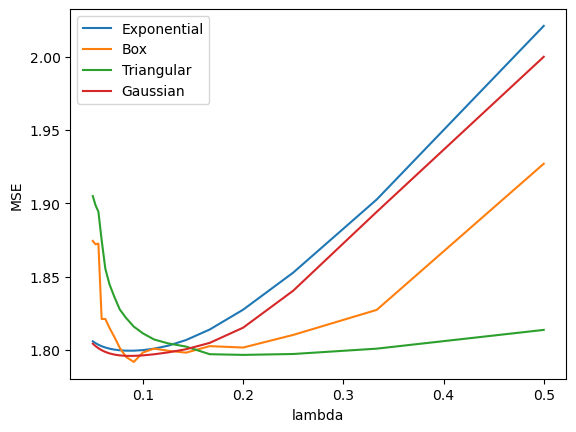

In [39]:
plt.plot(1/lamdas[1:], np.mean((xs_exp-xhs_exp)**2, -1)[1:])
plt.plot(1/lamdas[1:], np.mean((xs_box-xhs_box)**2, -1)[1:])
plt.plot(1/lamdas[1:], np.mean((xs_triang-xhs_triang)**2, -1)[1:])
plt.plot(1/lamdas[1:], np.mean((xs_gaussian-xhs_gaussian)**2, -1)[1:])
plt.legend(['Exponential', 'Box', 'Triangular', 'Gaussian'])
plt.xlabel('lambda')
plt.ylabel('MSE')

In [40]:
np.min(np.mean((xs_exp-xhs_exp)**2, -1)), np.min(np.mean((xs_box-xhs_box)**2, -1)), np.min(np.mean((xs_triang-xhs_triang)**2, -1)), np.min(np.mean((xs_gaussian-xhs_gaussian)**2, -1))

(1.9163846648692766,
 1.9093688594219451,
 1.9112685756088184,
 1.9112900563723012)

In [76]:
id_exp = np.argmin(np.mean((xs_exp-xhs_exp)**2, -1))
id_box = np.argmin(np.mean((xs_box-xhs_box)**2, -1))
id_triang = np.argmin(np.mean((xs_triang-xhs_triang)**2, -1))
id_gaussian = np.argmin(np.mean((xs_gaussian-xhs_gaussian)**2, -1))

In [36]:
# id_cv = 10

In [77]:
lamdas[id_exp], lamdas[id_box], lamdas[id_triang], lamdas[id_gaussian]

(10.0, 11.0, 4.0, 10.0)

## - G estimate

In [78]:
result_G = keceni_fit.G_estimate(i0s, T0s, n_X=1000)

In [79]:
YG_0, YG_1 = np.moveaxis(result_G, -1, 0)
YG_d = YG_1 - YG_0

In [80]:
YG_0, YG_1, YG_d

(-1.878642645952544, 2.2599252013955993, 4.138567847348144)

## - KECENI

In [81]:
result_AIPW = keceni_fit.kernel_AIPW(
    i0s, T0s, tqdm=tqdm
)

AIPW: 100%|██████████| 1000/1000 [00:07<00:00, 141.68it/s]


In [85]:
# exponential kernel
YDR_0_exp, YDR_1_exp = np.moveaxis(result_AIPW.est(lamdas, exponential_kernel), -1, 0)
YDR_d_exp = YDR_1_exp - YDR_0_exp
YDR_0_exp[id_exp], YDR_1_exp[id_exp], YDR_d_exp[id_exp]

(-1.712949501208127, 2.210041865201522, 3.922991366409649)

In [86]:
# box kernel
YDR_0_box, YDR_1_box = np.moveaxis(result_AIPW.est(lamdas, box_kernel), -1, 0)
YDR_d_box = YDR_1_box - YDR_0_box
YDR_0_box[id_box], YDR_1_box[id_box], YDR_d_box[id_box]

(-1.7336511437464974, 2.2497182392956505, 3.983369383042148)

In [87]:
# triangular kernel
YDR_0_triang, YDR_1_triang = np.moveaxis(result_AIPW.est(lamdas, triangular_kernel), -1, 0)
YDR_d_triang = YDR_1_triang - YDR_0_triang
YDR_0_triang[id_triang], YDR_1_triang[id_triang], YDR_d_triang[id_triang]

(-1.761505760469955, 2.276969600213263, 4.038475360683218)

In [88]:
# gaussian kernel
YDR_0_gaussian, YDR_1_gaussian = np.moveaxis(result_AIPW.est(lamdas, gaussian_kernel), -1, 0)
YDR_d_gaussian = YDR_1_gaussian - YDR_0_gaussian
YDR_0_gaussian[id_gaussian], YDR_1_gaussian[id_gaussian], YDR_d_gaussian[id_gaussian]

(-1.7483872431058638, 2.256638457984353, 4.005025701090217)